# Project 3 - Step 5: Post-processing - threshold, smoothing and STL export

The optimizer gives a density between 0 and 1 for every voxel. To make a part:

1. **Threshold**: keep voxels with density ≥ t (e.g. 0.5) → solid region
2. **Remove floating islands**: small pieces not connected to the main structure (optimizer leftovers)
3. **Surface**: *marching cubes* on the density field → closed triangle surface exactly at density = t
   (between voxel centres, so it already follows the gray transition instead of the voxel boundary)
4. **Smoothing**: remove the voxel "stairs"
   - *Laplacian*: move every vertex towards the average of its neighbours → smooth, but the part **shrinks**
   - *Taubin* (chosen): a Laplacian step (λ = 0.5) followed by an "un-shrinking" step (μ = -0.53) → smooth
     **without shrinking**
   - optional *Gaussian pre-blur* of the densities (σ in voxels) before marching cubes (tested below, off by default)
5. **Export** as STL (the writer from Step 3) and check that the surface is closed (every edge shared by 2 triangles)

Core code: `topopt3d/postprocess.py` (`smooth_surface`), tests: `tests/test_postprocess.py`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

from topopt3d import VoxelMesh, BoundaryConditions, TOSettings, run_topopt, smooth_surface, write_stl, read_stl
from topopt3d.postprocess import is_watertight

os.makedirs("results", exist_ok=True)
pv.global_theme.background = "white"


def render(tri, title="", color="#4d8fd6", camera=None):
    """Off-screen PyVista picture of a triangle surface (for the notebook)."""
    t = np.asarray(tri).reshape(-1, 3)
    n = len(t) // 3
    surf = pv.PolyData(t, np.column_stack([np.full(n, 3), np.arange(3 * n).reshape(n, 3)]).ravel()).clean()
    p = pv.Plotter(off_screen=True, window_size=(900, 560))
    p.add_mesh(surf, color=color, smooth_shading=True, specular=0.3)
    p.camera_position = camera or "iso"
    p.camera.zoom(1.2)
    img = p.screenshot(return_img=True)
    p.close()
    return img


def show_row(images, titles, size=(18, 4.5)):
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, img, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

## 1. Optimize the bracket (same as Step 3)

In [2]:
mesh = VoxelMesh.from_stl("sample_parts/bracket_with_hole.stl", resolution=40)
h = mesh.size[0]
lo, hi = mesh.bounds
bc = BoundaryConditions(mesh)
bc.fix(mesh.nodes_where(lambda x, y, z: np.hypot(x - 12, y - 20) < 7 + 0.75 * h))
bc.load(mesh.nodes_where(lambda x, y, z: (x > hi[0] - 1e-6) & (np.abs(y - 20) < 1e-6)), (0, -1, 0))
result = run_topopt(mesh, bc, TOSettings(volfrac=0.25, penal=3, rmin=1.5, max_iter=120))
x = result.x
print(mesh)
print(f"converged = {result.converged}, {result.iterations} iterations, {result.time:.1f} s, c = {result.compliance:.4f}")
print(f"densities: {np.mean(x > 0.9):.0%} above 0.9, {np.mean(x < 0.1):.0%} below 0.1, "
      f"{np.mean((x >= 0.1) & (x <= 0.9)):.0%} gray (0.1-0.9)")

VoxelMesh(grid 40 x 20 x 8, voxel [2.0, 2.0, 2.0], 6144 elements, 7560 nodes, 22680 DOFs)
converged = True, 41 iterations, 34.7 s, c = 9.3517
densities: 16% above 0.9, 61% below 0.1, 22% gray (0.1-0.9)


## 2. Effect of the threshold
Lower threshold → more material kept (thicker members); higher → thinner, may disconnect members.
The optimizer's target was 25 % of the part volume.

threshold solid voxels  surface volume % of part islands removed closed
      0.3         1612         12979.0     26.4%               0 True


      0.5         1316         10007.8     20.4%               0 True


      0.7         1224          6950.7     14.1%               0 True


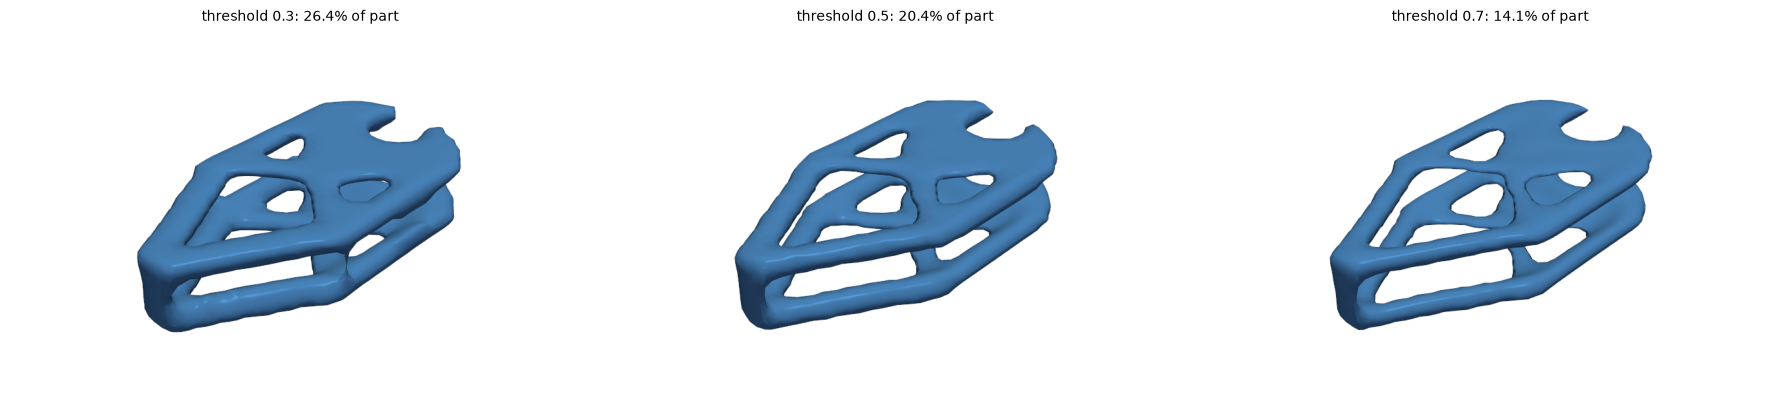

In [3]:
part_volume = mesh.n_elem * np.prod(mesh.size)
imgs, titles = [], []
print(f"{'threshold':>9s} {'solid voxels':>12s} {'surface volume':>15s} {'% of part':>9s} {'islands removed':>15s} closed")
for t in (0.3, 0.5, 0.7):
    tri, info = smooth_surface(mesh, x, threshold=t)
    print(f"{t:9.1f} {info['solid_voxels']:12d} {info['volume']:15.1f} {100 * info['volume'] / part_volume:8.1f}% "
          f"{info['islands_removed']:15d} {info['watertight']}")
    imgs.append(render(tri)); titles.append(f"threshold {t}: {100 * info['volume'] / part_volume:.1f}% of part")
show_row(imgs, titles)

## 3. Smoothing method (threshold 0.5)

method                           triangles    volume   vs raw
raw marching cubes                    5108   10536.0    +0.0%


Laplacian, 20 it.                     5108    5117.5   -51.4%


Taubin, 20 it.                        5108   10007.8    -5.0%


Taubin, 20 it. + blur σ = 0.5         5020    9341.0   -11.3%


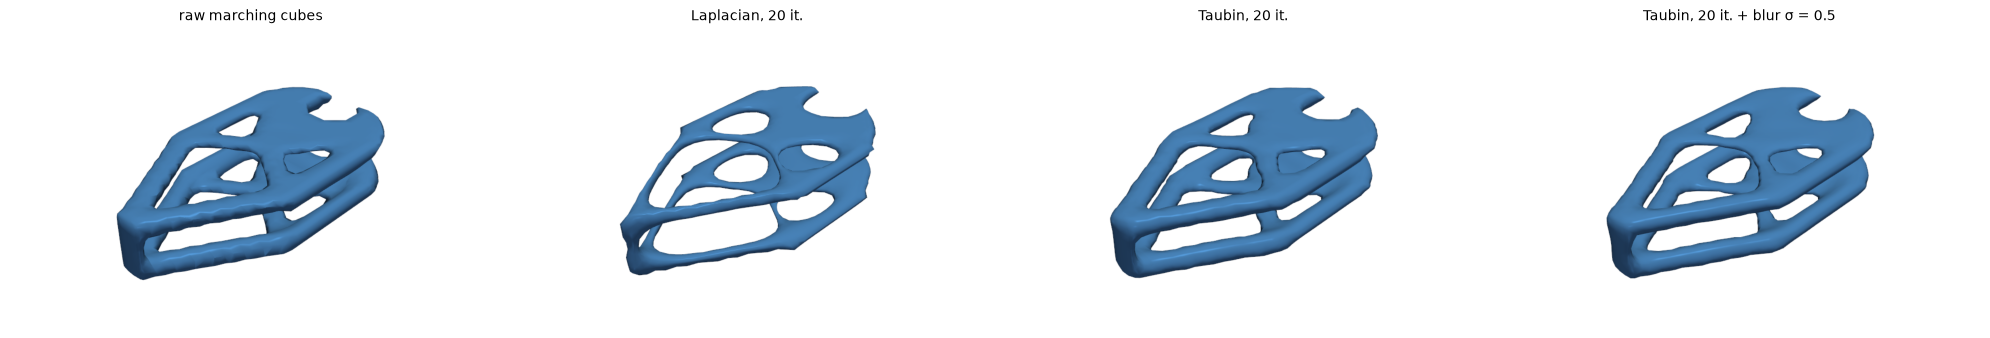

In [4]:
cases = [("none", 0, 0.0, "raw marching cubes"), ("laplacian", 20, 0.0, "Laplacian, 20 it."),
         ("taubin", 20, 0.0, "Taubin, 20 it."), ("taubin", 20, 0.5, "Taubin, 20 it. + blur σ = 0.5")]
imgs, titles = [], []
raw_volume = None
print(f"{'method':32s} {'triangles':>9s} {'volume':>9s} {'vs raw':>8s}")
for method, it, sigma, label in cases:
    tri, info = smooth_surface(mesh, x, threshold=0.5, iterations=it, sigma=sigma, method=method)
    raw_volume = raw_volume or info["volume"]
    print(f"{label:32s} {info['n_triangles']:9d} {info['volume']:9.1f} {100 * (info['volume'] / raw_volume - 1):+7.1f}%")
    imgs.append(render(tri)); titles.append(label)
show_row(imgs, titles, size=(20, 4.2))

**Same comparison on a sphere** (r = 10, voxelized at resolution 30), where the exact shape is known.
Roughness = standard deviation of the distance of the surface points from the centre.

method                   volume (exact 4188.8)  mean r roughness
raw                      4236.3                  10.044     0.138


Laplacian 20             4044.7                   9.891     0.083


Taubin 20                4248.1                  10.053     0.067


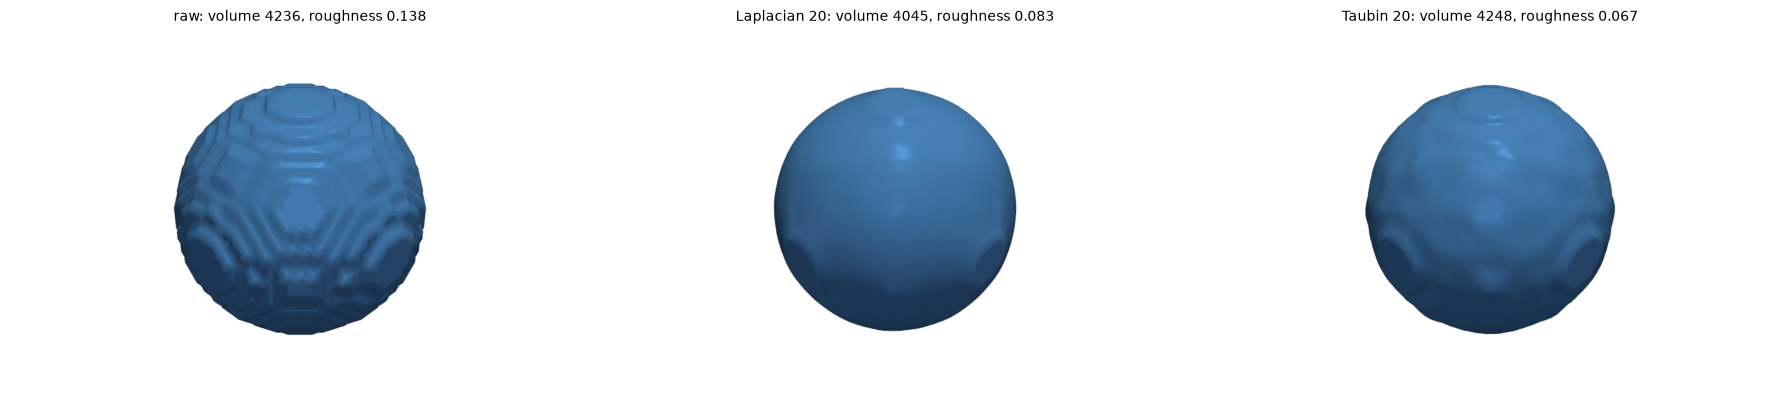

In [5]:
ball = VoxelMesh.from_stl("sample_parts/sphere_r10.stl", resolution=30)
ones = np.ones(ball.n_elem)
print(f"{'method':22s} {'volume':>8s} (exact {4 / 3 * np.pi * 1000:.1f}) {'mean r':>7s} {'roughness':>9s}")
imgs, titles = [], []
for method, it, label in [("none", 0, "raw"), ("laplacian", 20, "Laplacian 20"), ("taubin", 20, "Taubin 20")]:
    tri, info = smooth_surface(ball, ones, iterations=it, sigma=0, method=method)
    r = np.linalg.norm(tri.reshape(-1, 3), axis=1)
    print(f"{label:22s} {info['volume']:8.1f} {'':15s} {r.mean():7.3f} {r.std():9.3f}")
    imgs.append(render(tri)); titles.append(f"{label}: volume {info['volume']:.0f}, roughness {r.std():.3f}")
show_row(imgs, titles)

**Decision:** **Taubin smoothing, 20 iterations, no pre-blur, outer faces kept flat** is the default in the app.
- Laplacian smoothing shrinks: −3 % on the sphere and **−51 %** on the bracket (thin plates collapse into sheets).
- Taubin removes the voxel steps (sphere roughness 0.138 → 0.067) and keeps the volume (−5 % on the bracket).
- The pre-blur (σ = 0.5) removed another ~6 % of the bracket volume and thinned the members, because many members
  are only ~2 voxels thick at this resolution → off by default (still available as an option).
- Outer faces kept flat (added for the bridge, see `Step5_Bridge_PostProcessing_STL.ipynb`): surfaces on the outer
  planes of the design domain (mounting faces, supports) stay flat and the part never leaves the domain.
  *(Before that rule: Laplacian −68 %, Taubin −1.5 %, but the flat faces were rounded off.)*

## 4. Export the final part as STL and check it

saved results/bracket_optimized.stl: 5108 triangles, 249 kB
closed surface (watertight): True, open edges after reading back: 0
volume 10007.8 = 20.4% of the original part


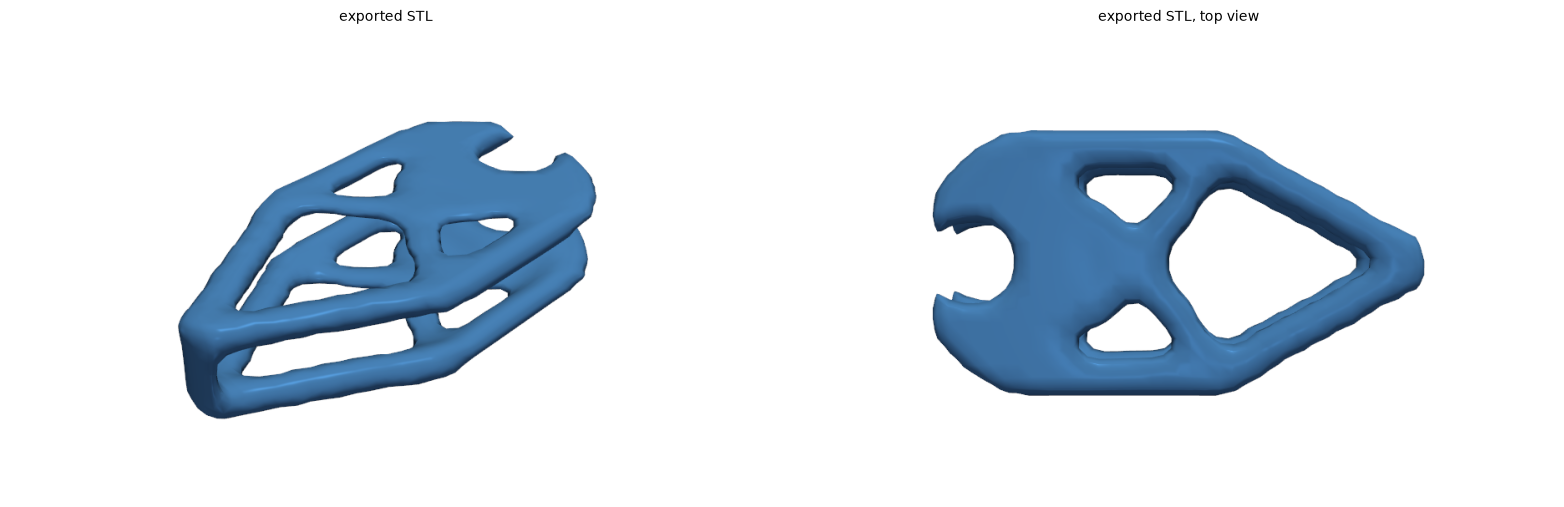

In [6]:
tri, info = smooth_surface(mesh, x, threshold=0.5, iterations=20, sigma=0.0, method="taubin")
path = "results/bracket_optimized.stl"
write_stl(path, tri)
back = read_stl(path)
print(f"saved {path}: {len(back)} triangles, {os.path.getsize(path) / 1024:.0f} kB")
faces = np.arange(3 * len(back)).reshape(-1, 3)
welded = pv.PolyData(back.reshape(-1, 3), np.column_stack([np.full(len(back), 3), faces]).ravel()).clean()
print(f"closed surface (watertight): {info['watertight']}, "
      f"open edges after reading back: {welded.extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False, non_manifold_edges=False).n_cells}")
print(f"volume {info['volume']:.1f} = {100 * info['volume'] / part_volume:.1f}% of the original part")
show_row([render(back, camera="iso"), render(back, camera="xy")], ["exported STL", "exported STL, top view"], size=(16, 5))